# Simple One Hidden Layer Neural Network — worked study copy

Answers prepared for revision with AI assistance. IBM / Skills Network source notices and embedded instructor explanations are retained. This is not a course submission.

Code completion and execution are tracked separately in the [solution progress report](../../../docs/SOLUTION_PROGRESS.md). Training may require a separate environment, external data, compute or provider credentials.

[Original reference](../../../courses/05-deep-learning-with-pytorch/notebooks/simple-one-hidden-layer-neural-network.ipynb) · [Course notes](../../../courses/05-deep-learning-with-pytorch/README.md)

**BOUNDED SMOKE RUN:** seed 42; CSVs sampled to at most 5,000 rows; one grid setting with two folds; training budgets capped; DataLoaders limited to 12 batches. These outputs are execution checks, not full-run model evaluations.

In [1]:
import os, itertools, random
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['TF_NUM_INTEROP_THREADS'] = '1'
os.environ['TF_NUM_INTRAOP_THREADS'] = '1'
import numpy as np
np.random.seed(42)
random.seed(42)
import pandas as pd
_read_csv = pd.read_csv
def _bounded_csv(*args, **kwargs):
    data = _read_csv(*args, **kwargs)
    return data.sample(n=5000,random_state=42) if len(data)>5000 else data
pd.read_csv = _bounded_csv
from sklearn.model_selection import GridSearchCV
_grid_fit = GridSearchCV.fit
def _bounded_grid(self, *args, **kwargs):
    grids = self.param_grid if isinstance(self.param_grid,list) else [self.param_grid]
    self.param_grid = [{k:list(v)[:1] for k,v in grid.items()} for grid in grids[:1]]
    self.cv = 2
    self.n_jobs = 1
    self.verbose = 0
    return _grid_fit(self,*args,**kwargs)
GridSearchCV.fit = _bounded_grid
try:
    import torch
except ImportError:
    torch = None
if torch is not None:
    torch.manual_seed(42)
    torch.set_num_threads(1)
    _loader_iter = torch.utils.data.DataLoader.__iter__
    def _bounded_loader(self):
        return itertools.islice(_loader_iter(self),12)
    torch.utils.data.DataLoader.__iter__ = _bounded_loader


<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


<h1>Simple One Hidden Layer Neural Network</h1>


**Estimated time needed**: 30 minutes


## Learning Objectives
After completing this lab you will be able to:
- Create a simple neural network in PyTorch


<h2>Table of Contents</h2>
<p>In this lab, you will use a single-layer neural network to classify non-linearly separable data in a 1-D database.</p>

<ol>
<li><a href="#Import-the-Libraries">Import the Libraries</a> 
</li>
<li><a href="#Neural-Network-Module-and-Training-Function">Neural Network Module and Training Function</a>     
</li>
<li><a href="#Define-the-Neural-Network,-Criterion-Function,-and-Optimizer">Define the Neural Network, Criterion Function, and Optimizer</a>     
</li>
 <li><a href="#Practice:-Train-the-Model-with-MSE-Loss-Function">Practice: Train the Model with MSE Loss Function</a>     
</li>
</ol>

<hr>


## Import the Libraries


We'll need the following libraries:


In [2]:
import torch
import torch.nn as nn
from torch import sigmoid
import matplotlib.pylab as plt
import numpy as np
torch.manual_seed(0)

Matplotlib is building the font cache; this may take a moment.


The following function is used to plot the model predictions:


In [3]:
def PlotStuff(X, Y, model, epoch, leg=True):
    plt.plot(X.numpy(), model(X).detach().numpy(), label='epoch ' + str(epoch))
    plt.plot(X.numpy(), Y.numpy(), 'r')
    plt.xlabel('x')
    if leg == True:
        plt.legend()
    else:
        pass

<!--Empty Space for separating topics-->


## Neural Network Module and Training Function


Define the activations and the output of the first linear layer as an attribute. Note that this is not good practice. 


In [4]:
class Net(nn.Module):

    def __init__(self, D_in, H, D_out):
        super(Net, self).__init__()
        self.linear1 = nn.Linear(D_in, H)
        self.linear2 = nn.Linear(H, D_out)
        self.a1 = None
        self.l1 = None
        self.l2 = None

    def forward(self, x):
        self.l1 = self.linear1(x)
        self.a1 = sigmoid(self.l1)
        self.l2 = self.linear2(self.a1)
        yhat = sigmoid(self.linear2(self.a1))
        return yhat

Define the training function:


In [5]:
def train(Y, X, model, optimizer, criterion, epochs=2):
    cost = []
    total = 0
    for epoch in itertools.islice(range(epochs), 2):
        total = 0
        for y, x in zip(Y, X):
            yhat = model(x)
            loss = criterion(yhat, y)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            total += loss.item()
        cost.append(total)
        if epoch % 300 == 0:
            PlotStuff(X, Y, model, epoch, leg=True)
            plt.show()
            model(X)
            plt.scatter(model.a1.detach().numpy()[:, 0], model.a1.detach().numpy()[:, 1], c=Y.numpy().reshape(-1))
            plt.title('activations')
            plt.show()
    return cost

<!--Empty Space for separating topics-->


## Create some Data


In [6]:
X = torch.arange(-20, 20, 1).view(-1, 1).type(torch.FloatTensor)
Y = torch.zeros(X.shape[0])
Y[(X[:, 0] > -4) & (X[:, 0] < 4)] = 1.0

<!--Empty Space for separating topics-->


## Define the Neural Network, Criterion Function, and Optimizer


Create the Cross-Entropy loss function: 


In [7]:
def criterion_cross(outputs, labels):
    out = -1 * torch.mean(labels * torch.log(outputs) + (1 - labels) * torch.log(1 - outputs))
    return out

Define the neural network and optimizer:


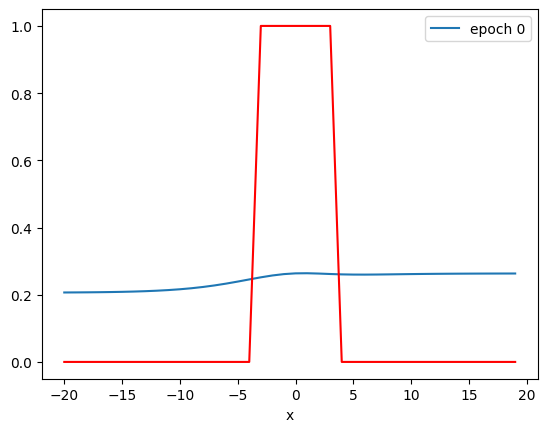

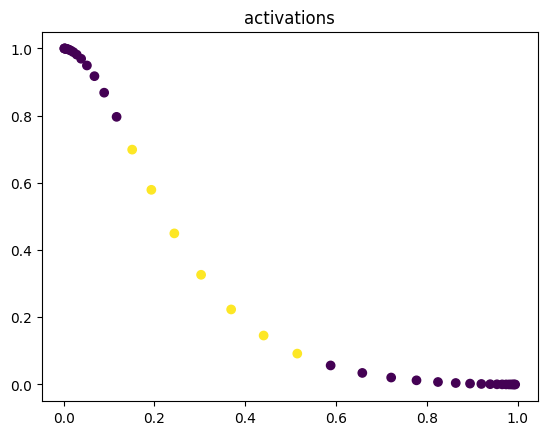

Text(0.5, 1.0, 'cross entropy loss')

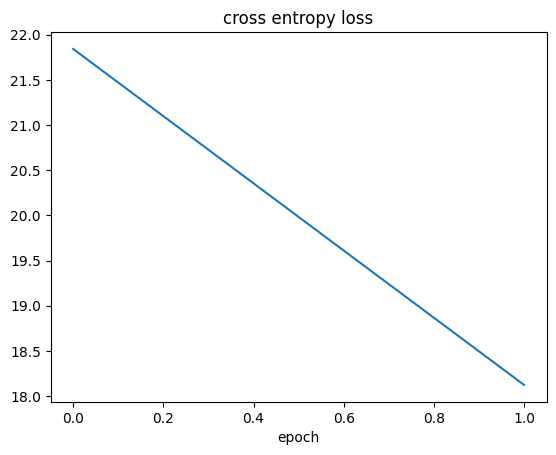

In [8]:
D_in = 1
H = 2
D_out = 1
learning_rate = 0.1
model = Net(D_in, H, D_out)
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
cost_cross = train(Y, X, model, optimizer, criterion_cross, epochs=2)
plt.plot(cost_cross)
plt.xlabel('epoch')
plt.title('cross entropy loss')

By examining the output of the activation function, you can see that by the 600th epoch, the data has been mapped to a linearly separable space.


We can make a prediction for an arbitrary one-tensor input.


In [9]:
x = torch.tensor([0.0])
yhat = model(x)
yhat

tensor([0.2130], grad_fn=<SigmoidBackward0>)

We can make predictions for some arbitrary input tensors.


In [10]:
X_ = torch.tensor([[0.0], [2.0], [3.0]])
Yhat = model(X_)
Yhat

tensor([[0.2130],
        [0.2048],
        [0.1999]], grad_fn=<SigmoidBackward0>)

We can apply a threshold to the prediction.


In [11]:
Yhat = Yhat > 0.5
Yhat

tensor([[False],
        [False],
        [False]])

## Practice: Train the Model with MSE Loss Function


Repeat the previous steps above by using the MSE cost or total loss: 


<repository>/.venv/lib/python3.11/site-packages/torch/nn/modules/loss.py:616: UserWarning: Using a target size (torch.Size([])) that is different to the input size (torch.Size([1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


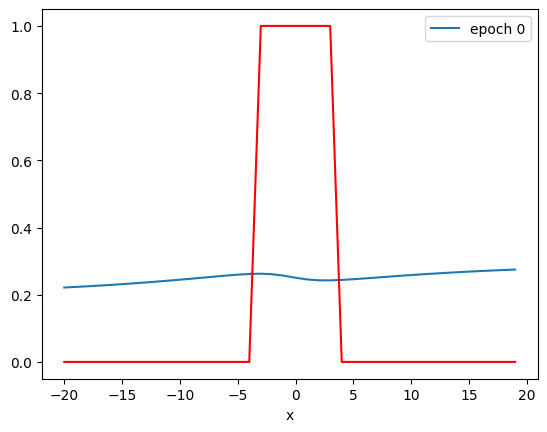

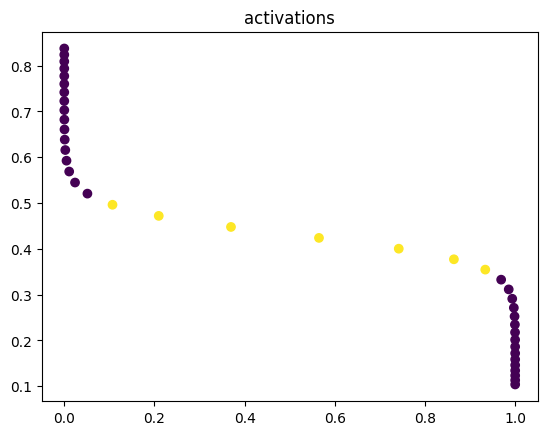

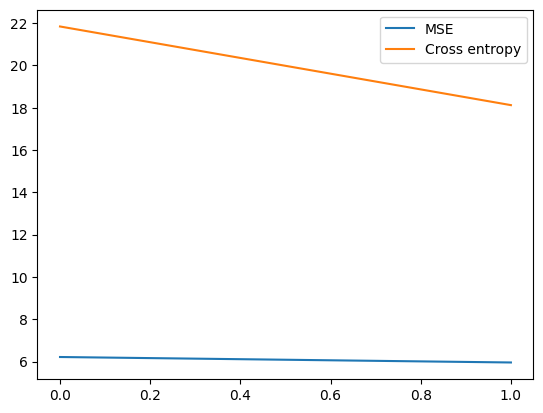

In [12]:
mse_model = Net(D_in, H, D_out)
mse_optimizer = torch.optim.SGD(mse_model.parameters(), lr=learning_rate)
cost_mse = train(Y, X, mse_model, mse_optimizer, nn.MSELoss(), epochs=2)
plt.plot(cost_mse, label='MSE')
plt.plot(cost_cross, label='Cross entropy')
plt.legend()
plt.show()

Double-click <b>here</b> for the solution.

<!-- 
learning_rate = 0.1
criterion_mse=nn.MSELoss()
model=Net(D_in,H,D_out)
optimizer=torch.optim.SGD(model.parameters(), lr=learning_rate)
cost_mse=train(Y,X,model,optimizer,criterion_mse,epochs=1000)
plt.plot(cost_mse)
plt.xlabel('epoch')
plt.title('MSE loss ')
-->


<h2>About the Authors:</h2> 

<a href="https://www.linkedin.com/in/joseph-s-50398b136/">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD. 


Other contributors: <a href="https://www.linkedin.com/in/michelleccarey/">Michelle Carey</a>, <a href="https://www.linkedin.com/in/jiahui-mavis-zhou-a4537814a">Mavis Zhou</a>


<!--
## Change Log

|  Date (YYYY-MM-DD) |  Version | Changed By  |  Change Description |
|---|---|---|---|
| 2020-09-23  | 2.0  | Shubham  |  Migrated Lab to Markdown and added to course repo in GitLab |
-->


<hr>



## <h3 align="center"> &#169; IBM Corporation. All rights reserved. <h3/>
